# CMIP6 torchcrop runs — time series

Cropland-weighted yield over 1851–2100, regional and national. Smooth lines are 21-year centred means.
ACCESS-ESM1-5's forcing starts in 1950, so the 1851–2100 figure uses the three full-record models for
its mean and range, with ACCESS-ESM1-5 dashed. Mixing them would put a step in the mean at 1951. The
later figures start in 1951 and use all four models.


**Reading these numbers**

* **Scope.** Torchcrop only, on calibrated parameters, for 4 models × 5 experiments, one run per
  model-experiment. Differences between experiments of one model include internal variability.
* **Cells.** The 59,304 cells every run simulated, weighted by cropland area. Each forcing has its own
  frame, and all 5,572 dropped cells lie outside the box the frames share.
* **Fixed crop system.** Cultivar, fertiliser and sowing (per-cell median of the MSWX SIMPLACE dates)
  do not change, so nothing here includes adaptation and sowing cannot respond to the forcing.
* **Wind** is an MSWX climatology in every run, so wind carries no scenario signal.
* **`hist-aer` holds CO₂ at 1850 (284 ppm)**; the other experiments follow their own CO₂. A contrast with
  `hist-aer` therefore mixes the climate effect with the CO₂ effect on the crop.
* **`yield_t_ha` excludes heat sterility.** `adjusted_yield_t_ha` = yield × (1 − heat stress). The
  calibration and evaluation use `yield_t_ha`, so it is the primary series here (see 04's sensitivity test).
* **No season 2015.** Historical runs end at harvest 2014, and SSP runs start with sowing in 2015.

## Findings

**Yield tracks CO₂ closely, and the two SSPs separate only after mid-century.**

* **Historical:** Europe's yield rises from about 3 t/ha in the 1850s to about 4 t/ha in 1985–2014. `hist-aer`, with CO₂ fixed at 1850, stays near 3 t/ha throughout, which is the clearest sign that CO₂ rather than climate drives the rise.
* **Future:** `ssp126` levels off about 8–10 % above the baseline as its CO₂ stabilises. `ssp370` keeps rising, to about +30 % by 2100.
* **Models:** ACCESS-ESM1-5 is the outlier, lowest in level and with `ssp126` falling back to about the baseline by 2100, while the other three hold near +10 %.
* **Join:** there is no large step across the missing 2015. Levels move by −0.16 to +0.19 t/ha between `historical` 2005–2014 and the SSPs in 2016–2025, which is within model differences.
* **MSWX:** its 4.06 t/ha in 2005–2014 lies within the model range of 3.83–4.30.

## 0. Setup

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from IPython.display import display

sys.path.insert(0, str(Path.cwd()))
import scenarios as sc
from cropmodelling4eu.evaluation.plots import save
from cropmodelling4eu.evaluation.style import SEQUENTIAL_CMAP, DIVERGING_CMAP, use_style

logging.basicConfig(level=logging.WARNING, force=True)
PALETTE = use_style("light")
plt.rcParams["figure.dpi"] = 90
FIGURES, TABLES = sc.table_dir("timeseries")
cells = sc.load_cells()
y = sc.cube("yield_t_ha")
EXP_COLOURS = {"historical": PALETTE["primary"], "hist-GHG": PALETTE["series_4"], "hist-aer": PALETTE["series_3"],
               "ssp126": PALETTE["series_1"], "ssp370": PALETTE["series_2"]}
MODEL_COLOURS = dict(zip(sc.MODELS, (PALETTE[f"series_{i}"] for i in (1, 2, 3, 5))))
SPAN = lambda s: f"{s[0]}–{s[1]}"

series = sc.regional_mean(y)
anomaly = 100.0 * (series / sc.clim(series.sel(experiment="historical"), sc.BASELINE) - 1.0)
smooth = lambda s: s.rolling(year=21, center=True, min_periods=15).mean()
LONG_RECORD = [m for m in sc.MODELS if m != "ACCESS-ESM1-5"]


def ensemble(ax, data, experiments, smoother=smooth):
    for e in experiments:
        block = smoother(data.sel(experiment=e))
        ax.fill_between(block.year, block.min("model"), block.max("model"), color=EXP_COLOURS[e], alpha=0.18, lw=0)
        ax.plot(block.year, block.mean("model"), color=EXP_COLOURS[e], lw=1.5, label=e)
    ax.axvspan(*sc.BASELINE, color="k", alpha=0.05, lw=0)

print(f"{cells.n} cells; outputs in {FIGURES.parent}")

59304 cells; outputs in /data01/FDS/muduchuru/Data/SIMPLACE/cropmodelling4eu/runs/winter_wheat/calibrated/cmip6/analysis/timeseries


## 1. Europe, 1851–2100

The grey band is the 1985–2014 baseline. Shading is the range of the three full-record models, and dashed lines are ACCESS-ESM1-5.

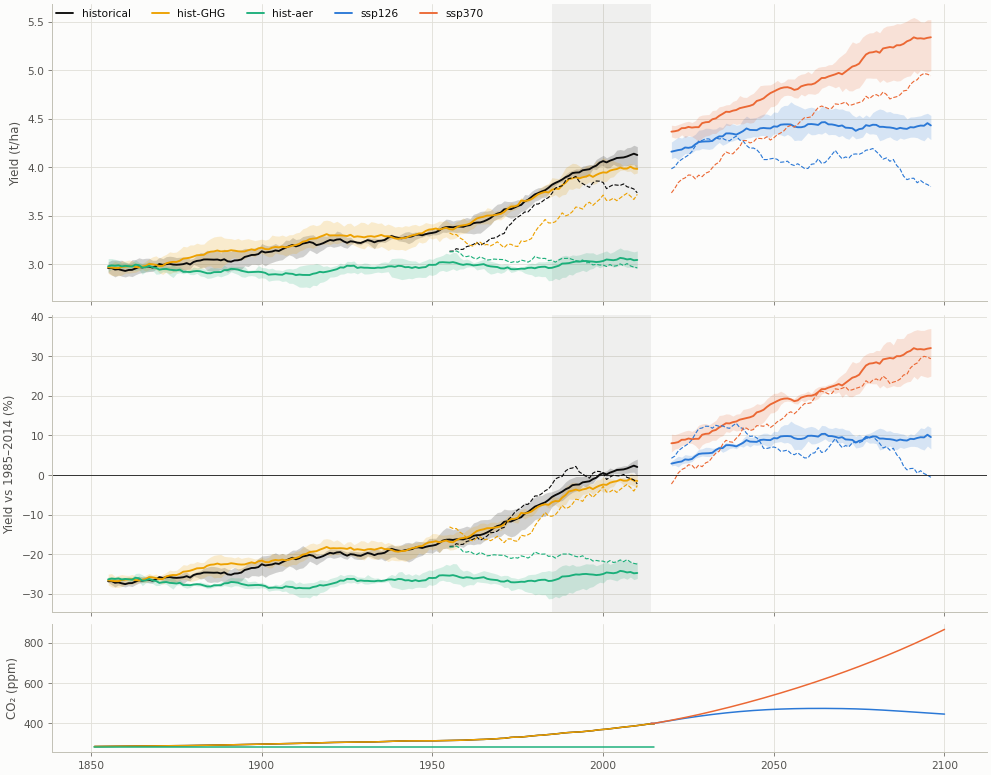

In [2]:
co2 = sc.co2_series()
fig, axes = plt.subplots(3, 1, figsize=(11.0, 8.6), sharex=True, layout="constrained", gridspec_kw={"height_ratios": [3, 3, 1.3]})
ensemble(axes[0], series.sel(region="Europe", model=LONG_RECORD), sc.EXPERIMENTS)
axes[0].set_ylabel("Yield (t/ha)")
axes[0].legend(frameon=False, ncol=5)
ensemble(axes[1], anomaly.sel(region="Europe", model=LONG_RECORD), sc.EXPERIMENTS)
for ax, data in zip(axes, (series, anomaly)):
    for e in sc.EXPERIMENTS:
        s = smooth(data.sel(region="Europe", model="ACCESS-ESM1-5", experiment=e))
        ax.plot(s.year, s, color=EXP_COLOURS[e], lw=0.9, ls="--")
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set_ylabel("Yield vs 1985–2014 (%)")
for e in sc.EXPERIMENTS:
    axes[2].plot(co2.index, co2[e], color=EXP_COLOURS[e], lw=1.2)
axes[2].set_ylabel("CO₂ (ppm)")
save(fig, "europe_full", FIGURES)
plt.show()

Each model on its own, with the unsmoothed seasons behind the 21-year mean. The seasons show how large a single year is against the signal:

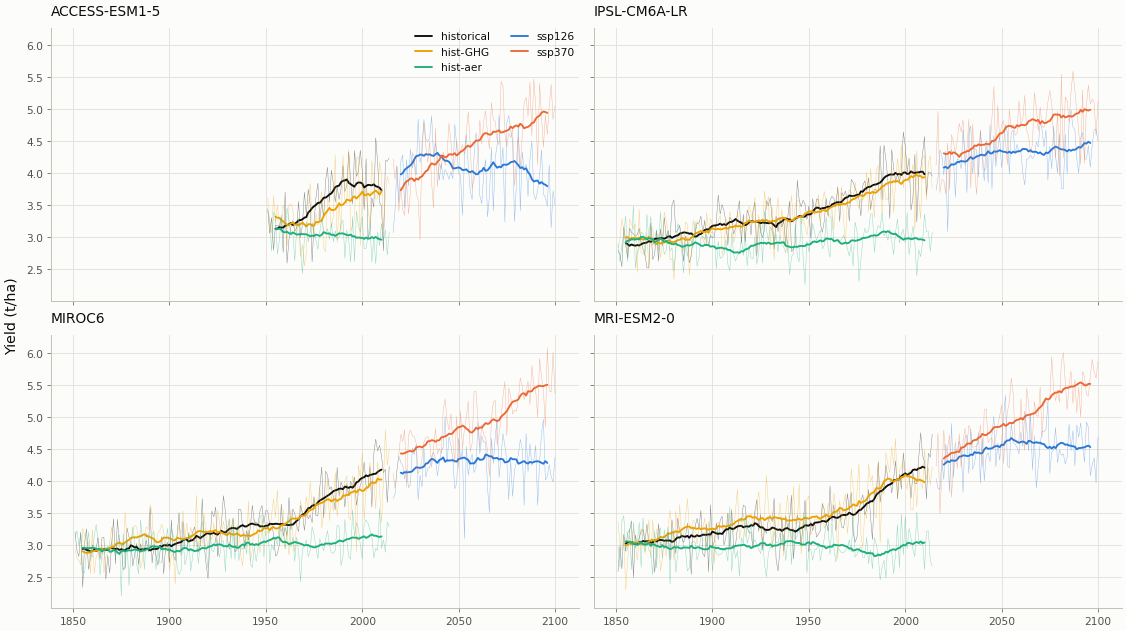

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.0), sharex=True, sharey=True, layout="constrained")
for ax, m in zip(axes.ravel(), sc.MODELS):
    for e in sc.EXPERIMENTS:
        s = series.sel(region="Europe", model=m, experiment=e)
        ax.plot(s.year, s, color=EXP_COLOURS[e], lw=0.35, alpha=0.5)
        ax.plot(s.year, smooth(s), color=EXP_COLOURS[e], lw=1.5, label=e)
    ax.set_title(m)
axes[0, 0].legend(frameon=False, ncol=2)
fig.supylabel("Yield (t/ha)")
save(fig, "europe_models", FIGURES)
plt.show()

## 2. Against the MSWX run

Historical and ssp370 spliced across the missing 2015, around the MSWX torchcrop run. The model lines should straddle MSWX in level; year-to-year matches are not expected.

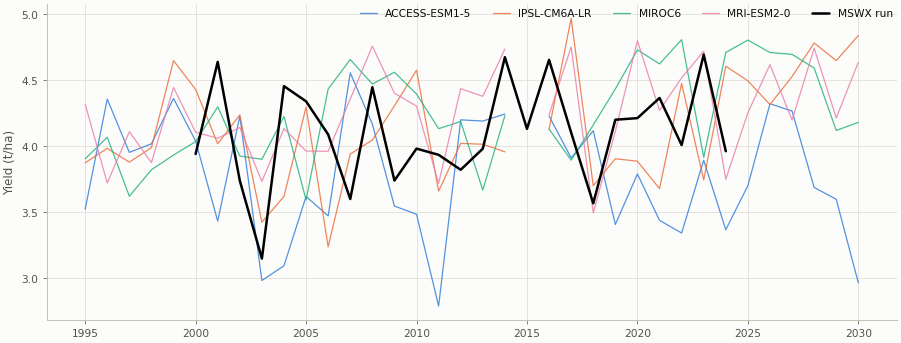

Level either side of the historical→SSP join (t/ha). A large step would mean the two are not one series:


,historical 2005–2014,ssp126 2016–2025,ssp370 2016–2025,MSWX 2005–2014,MSWX 2016–2024
ACCESS-ESM1-5,3.83,3.85,3.72,4.06,4.2
IPSL-CM6A-LR,4.01,4.05,4.16,4.06,4.2
MIROC6,4.23,4.07,4.42,4.06,4.2
MRI-ESM2-0,4.30,4.19,4.29,4.06,4.2


In [4]:
mswx = sc.regional_mean(sc.mswx_cube()).sel(region="Europe")
fig, ax = plt.subplots(figsize=(10.0, 3.8), layout="constrained")
for m in sc.MODELS:
    for e in ("historical", "ssp370"):
        s = series.sel(region="Europe", model=m, experiment=e).sel(year=slice(1995, 2030))
        ax.plot(s.year, s, color=MODEL_COLOURS[m], lw=1.0, alpha=0.8, label=m if e == "historical" else None)
ax.plot(mswx.year, mswx, "k", lw=2.0, label="MSWX run")
ax.set(ylabel="Yield (t/ha)")
ax.legend(frameon=False, ncol=5)
save(fig, "vs_mswx", FIGURES)
plt.show()
window = lambda s, a, b: float(s.sel(year=slice(a, b)).mean())
seam = pd.DataFrame({m: {"historical 2005–2014": window(series.sel(region="Europe", model=m, experiment="historical"), 2005, 2014),
                         "ssp126 2016–2025": window(series.sel(region="Europe", model=m, experiment="ssp126"), 2016, 2025),
                         "ssp370 2016–2025": window(series.sel(region="Europe", model=m, experiment="ssp370"), 2016, 2025)} for m in sc.MODELS}).T
seam["MSWX 2005–2014"] = window(mswx, 2005, 2014)
seam["MSWX 2016–2024"] = window(mswx, 2016, 2024)
seam.to_csv(TABLES / "seam_levels.csv")
print("Level either side of the historical→SSP join (t/ha). A large step would mean the two are not one series:")
display(seam.round(2))

## 3. Regions

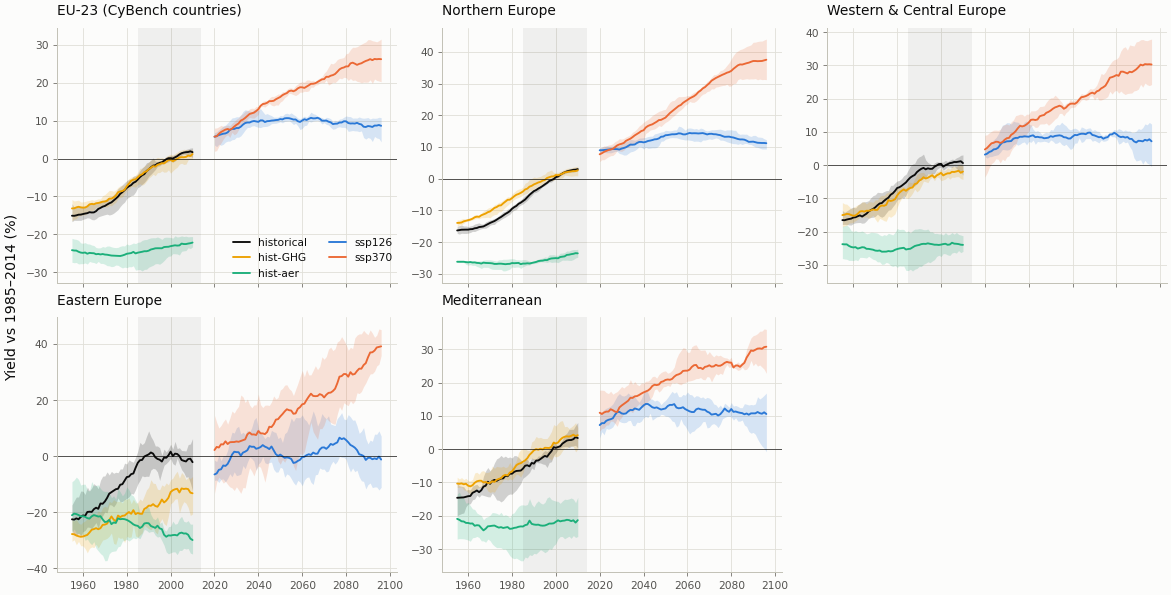

In [5]:
regions = [r for r in series.region.values if r != "Europe"]
fig, axes = plt.subplots(2, 3, figsize=(13.0, 6.6), sharex=True, layout="constrained")
for ax, r in zip(axes.ravel(), regions):
    ensemble(ax, anomaly.sel(region=r).sel(year=slice(1951, None)), sc.EXPERIMENTS)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(sc.REGION_NAMES[r])
axes[0, 0].legend(frameon=False, ncol=2)
axes[1, 2].set_visible(len(regions) > 5)
fig.supylabel("Yield vs 1985–2014 (%)")
save(fig, "regions", FIGURES)
plt.show()

## 4. Forcing differences through time

The paired difference per model and year, which removes most of the shared crop response. The two historical climate runs still have different weather, so only the smoothed line is meaningful.

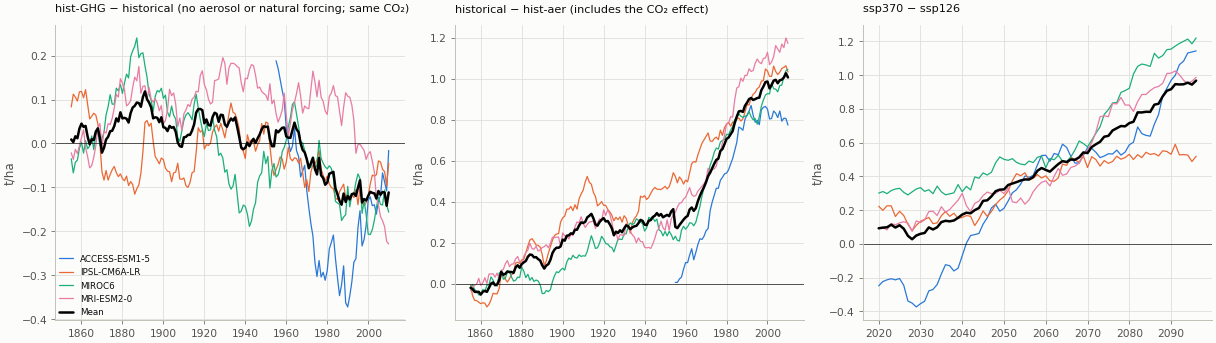

In [6]:
pairs = {"hist-GHG − historical (no aerosol or natural forcing; same CO₂)": ("hist-GHG", "historical"),
         "historical − hist-aer (includes the CO₂ effect)": ("historical", "hist-aer"),
         "ssp370 − ssp126": ("ssp370", "ssp126")}
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8), layout="constrained")
for ax, (name, (a, b)) in zip(axes, pairs.items()):
    d = smooth(series.sel(region="Europe", experiment=a) - series.sel(region="Europe", experiment=b)).dropna("year", how="all")
    for m in sc.MODELS:
        ax.plot(d.year, d.sel(model=m), color=MODEL_COLOURS[m], lw=1.0, label=m)
    ax.plot(d.year, d.mean("model"), "k", lw=2.0, label="Mean")
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(name, fontsize=9)
    ax.set_ylabel("t/ha")
axes[0].legend(frameon=False, fontsize=7)
save(fig, "forcing_differences", FIGURES)
plt.show()

## 5. Interannual variability

Rolling 21-year standard deviation of each season's departure from the 21-year mean, as a share of that mean. A domain mean hides variability that offsets between regions, so the same is shown for Western & Central Europe and the Mediterranean.

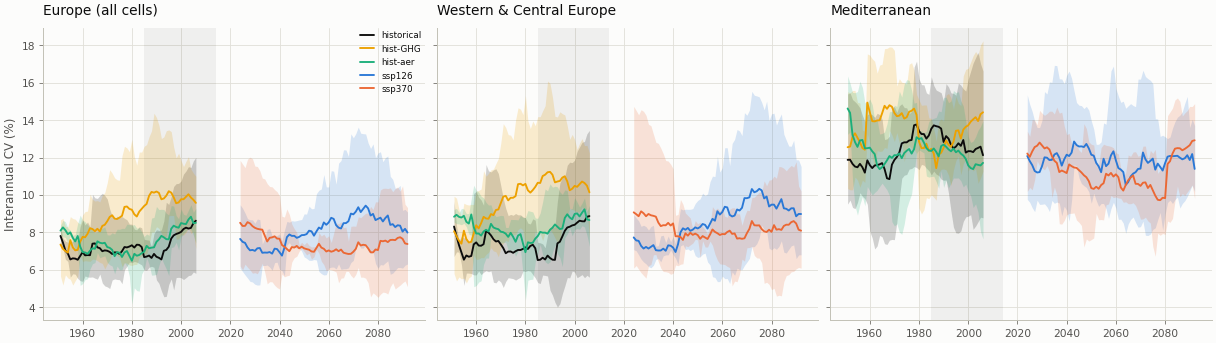

In [7]:
def rolling_cv(s):
    centre = smooth(s)
    return 100.0 * (s - centre).rolling(year=21, center=True, min_periods=15).std() / centre

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8), sharey=True, layout="constrained")
for ax, r in zip(axes, ("Europe", "WCE", "MED")):
    ensemble(ax, rolling_cv(series.sel(region=r)).sel(year=slice(1951, None)), sc.EXPERIMENTS, smoother=lambda s: s)
    ax.set_title(sc.REGION_NAMES[r])
axes[0].set_ylabel("Interannual CV (%)")
axes[0].legend(frameon=False, fontsize=7)
save(fig, "variability", FIGURES)
plt.show()

## 6. The crop processes behind the yield

Domain means of the outputs torchcrop writes. Notebook 05 uses these for the yield decomposition.

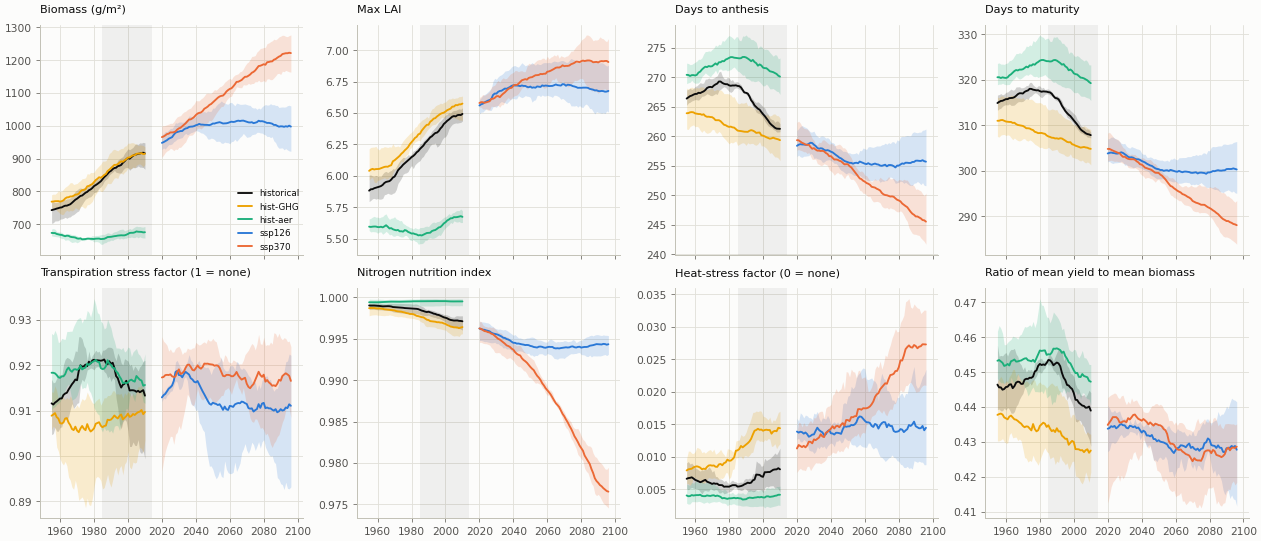

In [8]:
PROCESS = {"biomass_g_m2": "Biomass (g/m²)", "max_lai": "Max LAI", "days_to_anthesis": "Days to anthesis", "days_to_maturity": "Days to maturity",
           "tranrf_mean": "Transpiration stress factor (1 = none)", "nni_mean": "Nitrogen nutrition index", "heat_stress_factor": "Heat-stress factor (0 = none)"}
fig, axes = plt.subplots(2, 4, figsize=(14.0, 6.0), sharex=True, layout="constrained")
for ax, (v, label) in zip(axes.ravel(), PROCESS.items()):
    ensemble(ax, sc.regional_mean(sc.cube(v), regions=("Europe",)).sel(region="Europe").sel(year=slice(1951, None)), sc.EXPERIMENTS)
    ax.set_title(label, fontsize=9)
harvest_index = sc.regional_mean(y, regions=("Europe",)) * 100.0 / sc.regional_mean(sc.cube("biomass_g_m2"), regions=("Europe",))
ensemble(axes[1, 3], harvest_index.sel(region="Europe").sel(year=slice(1951, None)), sc.EXPERIMENTS)
axes[1, 3].set_title("Ratio of mean yield to mean biomass", fontsize=9)
axes[0, 0].legend(frameon=False, fontsize=7)
save(fig, "processes", FIGURES)
plt.show()

## 7. Yield against CO₂

Europe, per season. Separation between `ssp126` and `ssp370` at the same CO₂ shows that yield does not depend on CO₂ alone.

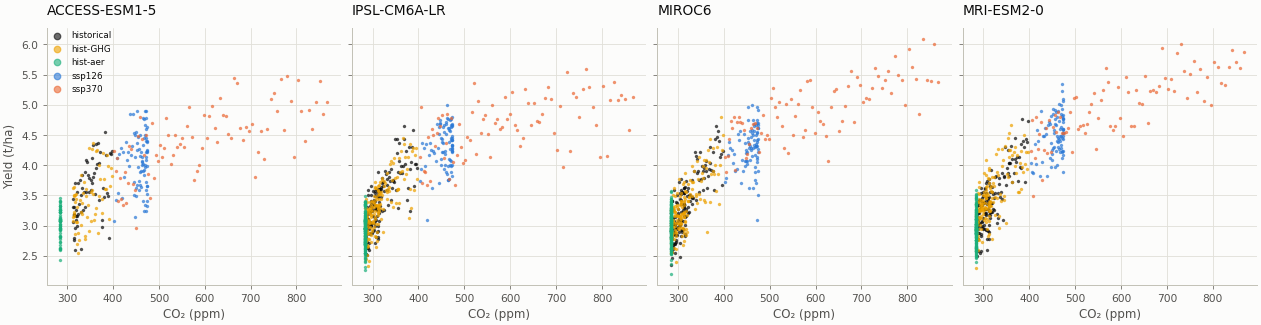

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14.0, 3.6), sharex=True, sharey=True, layout="constrained")
for ax, m in zip(axes, sc.MODELS):
    for e in sc.EXPERIMENTS:
        s = series.sel(region="Europe", model=m, experiment=e).to_series().dropna()
        ax.scatter(co2[e].reindex(s.index), s, s=3, color=EXP_COLOURS[e], label=e, alpha=0.6)
    ax.set(title=m, xlabel="CO₂ (ppm)")
axes[0].set_ylabel("Yield (t/ha)")
axes[0].legend(frameon=False, fontsize=7, markerscale=3)
save(fig, "yield_vs_co2", FIGURES)
plt.show()

## 8. Countries

CyBench countries with at least 2,000 km² of cropland, 1951–2100.

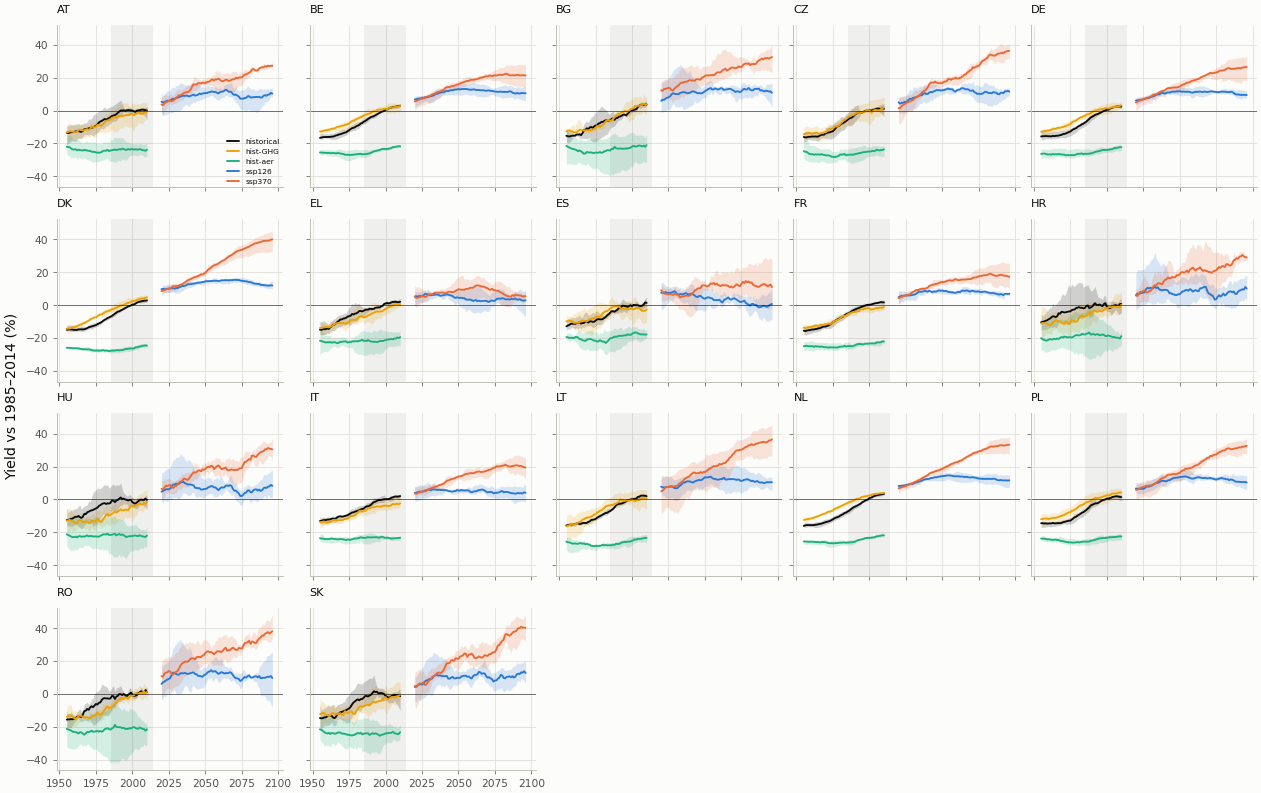

In [10]:
countries = sc.country_series(y)
base = sc.clim(countries.sel(experiment="historical"), sc.BASELINE)
by_country = (100.0 * (countries / base - 1.0)).sel(year=slice(1951, None))
codes = list(by_country.country.values)
n_rows = int(np.ceil(len(codes) / 5))
fig, axes = plt.subplots(n_rows, 5, figsize=(14.0, 2.2 * n_rows), sharex=True, sharey=True, layout="constrained")
for ax, code in zip(axes.ravel(), codes):
    ensemble(ax, by_country.sel(country=code), sc.EXPERIMENTS)
    ax.axhline(0, color="k", lw=0.4)
    ax.set_title(code, fontsize=9)
for ax in axes.ravel()[len(codes):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=6)
fig.supylabel("Yield vs 1985–2014 (%)")
save(fig, "countries", FIGURES)
plt.show()